# Caminho B — Análise exploratória dos erros do KNN

**Pergunta:** o KNN erra mais ao prever empates, vitórias ou derrotas?

Estrutura simplificada: ler CSV → preparar médias históricas → treinar KNN → analisar erros → escrever conclusão. Sem K-means.

In [1]:
# Dados de partidas; coloque o CSV na pasta de arquivos do Colab.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Partidas_Tratadas.csv')
df['data'] = pd.to_datetime(df['data'])
df = df.sort_values(['time', 'data', 'fixture_id']).copy()
print(df.shape)
display(df.head())


(3446, 17)


,fixture_id,data,partida,time,team_id,local_visitante,adversario,adversario_id,resultado,league_id,season_id,state_id,Escanteios,Posse de bola (%),Gols,Cartões vermelhos,Cartões amarelos
0,378836,2017-01-27 19:45:00,Aberdeen vs Dundee,Aberdeen,273,home,Dundee,284,2,501,825,5,9,64.0,3.0,0,1.0
1,378943,2017-02-01 19:45:00,Celtic vs Aberdeen,Aberdeen,273,away,Celtic,53,0,501,825,5,0,32.0,0.0,0,3.0
2,378996,2017-02-04 15:00:00,Aberdeen vs Partick Thistle,Aberdeen,273,home,Partick Thistle,339,2,501,825,5,2,58.0,2.0,0,2.0
3,378129,2017-02-15 19:45:00,Aberdeen vs Motherwell,Aberdeen,273,home,Motherwell,309,2,501,825,5,6,56.0,7.0,0,2.0
4,379070,2017-02-19 13:00:00,Kilmarnock vs Aberdeen,Aberdeen,273,away,Kilmarnock,180,2,501,825,5,4,62.0,2.0,0,2.0


## 1. Criar as mesmas variáveis históricas

In [2]:
# Médias das últimas 5 partidas do time (sem incluir o jogo atual).
# São informações históricas, não o resultado da partida a prever.
df['pontos'] = df['resultado'].map({0: 0, 1: 1, 2: 3})
colunas = {'pontos': 'pontos_5', 'Gols': 'gols_5',
           'Escanteios': 'escanteios_5', 'Posse de bola (%)': 'posse_5'}
for coluna, nova in colunas.items():
    df[nova] = df.groupby('time')[coluna].transform(
        lambda x: x.shift(1).rolling(5, min_periods=3).mean()
    )

variaveis = ['pontos_5', 'gols_5', 'escanteios_5', 'posse_5']
df = df.dropna(subset=variaveis).copy()
print('Registros com histórico:', len(df))


Registros com histórico: 3370


## 2. Treinar e avaliar o KNN

Divisão cronológica de aproximadamente 80% para treino e 20% para teste. Usamos `StandardScaler` no `Pipeline`, pois o KNN depende de distâncias. Para manter o código simples, usamos K=35 (valor documentado em uma versão anterior do projeto), sem busca de hiperparâmetros.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

df = df.sort_values(['data', 'fixture_id']).reset_index(drop=True)
corte = int(len(df) * 0.8)
# Mantém a mesma data em apenas um conjunto, evitando dividir um mesmo dia.
data_corte = df.loc[corte, 'data'].normalize()
treino = df[df['data'] < data_corte].copy()
teste = df[df['data'] >= data_corte].copy()

modelo = Pipeline([
    ('padronizacao', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=35))
])
modelo.fit(treino[variaveis], treino['resultado'])
teste['previsto'] = modelo.predict(teste[variaveis])
teste['errou'] = teste['resultado'] != teste['previsto']
print('Treino:', len(treino), '| Teste:', len(teste))
print('Acurácia:', round(accuracy_score(teste['resultado'], teste['previsto']), 3))


Treino: 2692 | Teste: 678
Acurácia: 0.454


## 3. Visualização: matriz de confusão

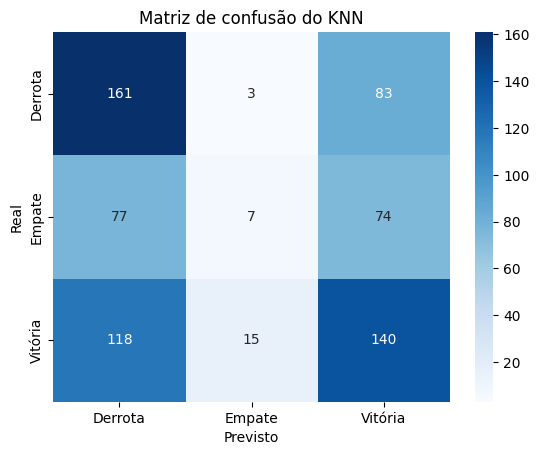

In [4]:
nomes = ['Derrota', 'Empate', 'Vitória']
matriz = confusion_matrix(teste['resultado'], teste['previsto'], labels=[0, 1, 2])
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=nomes, yticklabels=nomes)
plt.title('Matriz de confusão do KNN')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.show()


## 4. Visualização: taxa de erro por resultado

,partidas,erros,taxa_erro
classe,,,
Derrota,247,86,34.8
Empate,158,151,95.6
Vitória,273,133,48.7


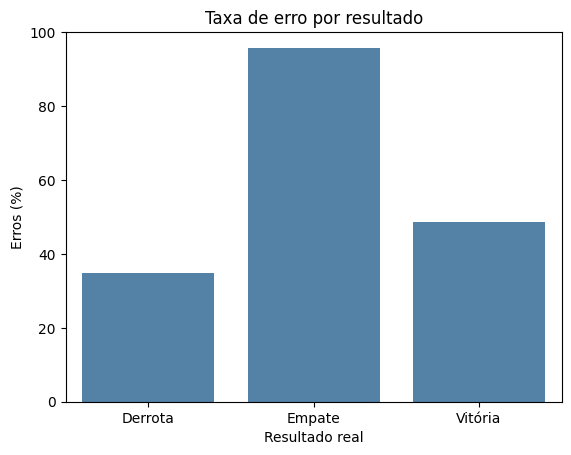

In [5]:
teste['classe'] = teste['resultado'].map({0:'Derrota', 1:'Empate', 2:'Vitória'})
resumo = teste.groupby('classe')['errou'].agg(['count', 'sum', 'mean'])
resumo.columns = ['partidas', 'erros', 'taxa_erro']
resumo['taxa_erro'] = (resumo['taxa_erro'] * 100).round(1)
display(resumo)

sns.barplot(x=resumo.index, y=resumo['taxa_erro'], color='steelblue')
plt.title('Taxa de erro por resultado')
plt.ylabel('Erros (%)')
plt.xlabel('Resultado real')
plt.ylim(0, 100)
plt.show()
